In [1]:
import os
import sys
import time

import numpy as np
import matplotlib.pyplot as plt

root_dir = os.path.abspath("..")
figs_dir = os.path.join(root_dir, "figs", "waveform_study_neural_flux_torque")
os.makedirs(figs_dir, exist_ok=True)
if root_dir not in sys.path:
    sys.path.append(root_dir)

from current_setpoints.models.machines import ieee_machine2_trained_neural_flux_and_torque
from current_setpoints.models.forward_model import ForwardModel, Fault
from current_setpoints.optimization import ActiveSetOptimizer, StaticOptimizer

CURR_MAX = 30.0
VOLT_MAX = 13.0
N_GRID = 60
SLSQP_OPTS = {"disp": False, "ftol": 1e-8, "maxiter": 500}

SPEEDS_RPM = [600.0, 1200.0, 1800.0]  # current limit only / knee / deep field weakening
TORQUE_FRACS = [0.3, 0.6, 0.9, 1.0]  # study A: torque targets, fractions of the static max torque
RHO_SPEEDS_RPM = [1200.0, 1500.0, 1800.0]  # study B: where the dynamic current varies (at 600 rpm dynamic = static)
RHO_TORQUE_FRAC = 0.95  # study B: torque target, fraction of the static max torque
RHO_VALUES = [0.0, 1e2, 1e3, 1e4, 1e5, 1e6]  # study B: smoothness penalty rho (PDF 11 §6, E02); at 1800 rpm
                                            # the trajectory is constant from ~1e5 on, ~1e2 changes almost nothing

drive = ieee_machine2_trained_neural_flux_and_torque(curr_max=CURR_MAX, volt_max=VOLT_MAX)
fwd = ForwardModel(drive, n_theta=700, fault=Fault(()))  # healthy mode
const_mech_speed = 30.0 / (np.pi * drive.n_ppairs)
optimizer_static = StaticOptimizer(fwd, opts=SLSQP_OPTS)
optimizer_dynamic = ActiveSetOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID)

In [2]:
THETA = fwd.vec_theta[:-1]  # 700 angles over one electrical period
N_T = THETA.size
DEG = np.rad2deg(THETA)


def dense_waveforms(omega, curr_dq):
    """Phase currents and voltages at 700 angles, the way the drive would see them.
    Static (curr_dq shape (dim,)): constant current. Dynamic (shape (n_grid, dim)): the current
    runs linearly between nodes and the voltage includes the dynamic term (PDF 11 eq. 3/7):
        v(theta) = h(theta) [R i + omega J psi(i) + omega L(i) di/dtheta],  di/dtheta constant per segment
    (U, L, back-EMF evaluated at the current at that angle). Returns (i_ph, v_ph), shape (n_phases, N_T)."""
    if curr_dq.ndim == 1:
        i_dq = np.tile(curr_dq, (N_T, 1))
        didth = np.zeros_like(i_dq)
    else:
        n_grid = curr_dq.shape[0]
        dth = 2 * np.pi / n_grid
        seg = np.minimum((THETA // dth).astype(int), n_grid - 1)
        nxt = (seg + 1) % n_grid
        frac = (THETA - seg * dth) / dth
        i_dq = curr_dq[seg] + frac[:, None] * (curr_dq[nxt] - curr_dq[seg])
        didth = (curr_dq[nxt] - curr_dq[seg]) / dth
    i_ph = np.empty((drive.n_phases, N_T))
    v_ph = np.empty((drive.n_phases, N_T))
    for t in range(N_T):
        i_ph[:, t] = fwd.phase_map_at_theta(t) @ i_dq[t]
        gU, gL, bV = fwd.volt_map_at_theta(t, omega, i_dq[t])
        v_ph[:, t] = gU @ i_dq[t] + bV + omega * (gL @ didth[t])
    return i_ph, v_ph


def metrics(i_ph, v_ph):
    """Copper-loss proxy (mean over theta of sum_k i_k^2, same quantity as the maps), peak current
    and voltage over all phases and angles, and the harmonic content of phase a: 3rd-harmonic share
    |I_3|/|I_1| and the share of all other harmonics (h != 1, 3), where the dynamic ripple shows up."""
    spec = 2.0 * np.abs(np.fft.rfft(i_ph[0])) / N_T
    other = np.sqrt(max(np.sum(spec[2:] ** 2) - spec[3] ** 2, 0.0))
    return {
        "copper_loss": float(np.mean(np.sum(i_ph**2, axis=0))),
        "I_peak": float(np.max(np.abs(i_ph))),
        "V_peak": float(np.max(np.abs(v_ph))),
        "h3_share": float(spec[3] / spec[1]),
        "other_share": float(other / spec[1]),
        "spectrum": spec,
    }


def n_joint_solves(sol):
    return sum(1 for h in sol.diagnostics.get("history", []) if "solve_success" in h)

  600 rpm, 30%: 10s
  600 rpm, 60%: 10s
  600 rpm, 90%: 12s
  600 rpm, 100%: 23s


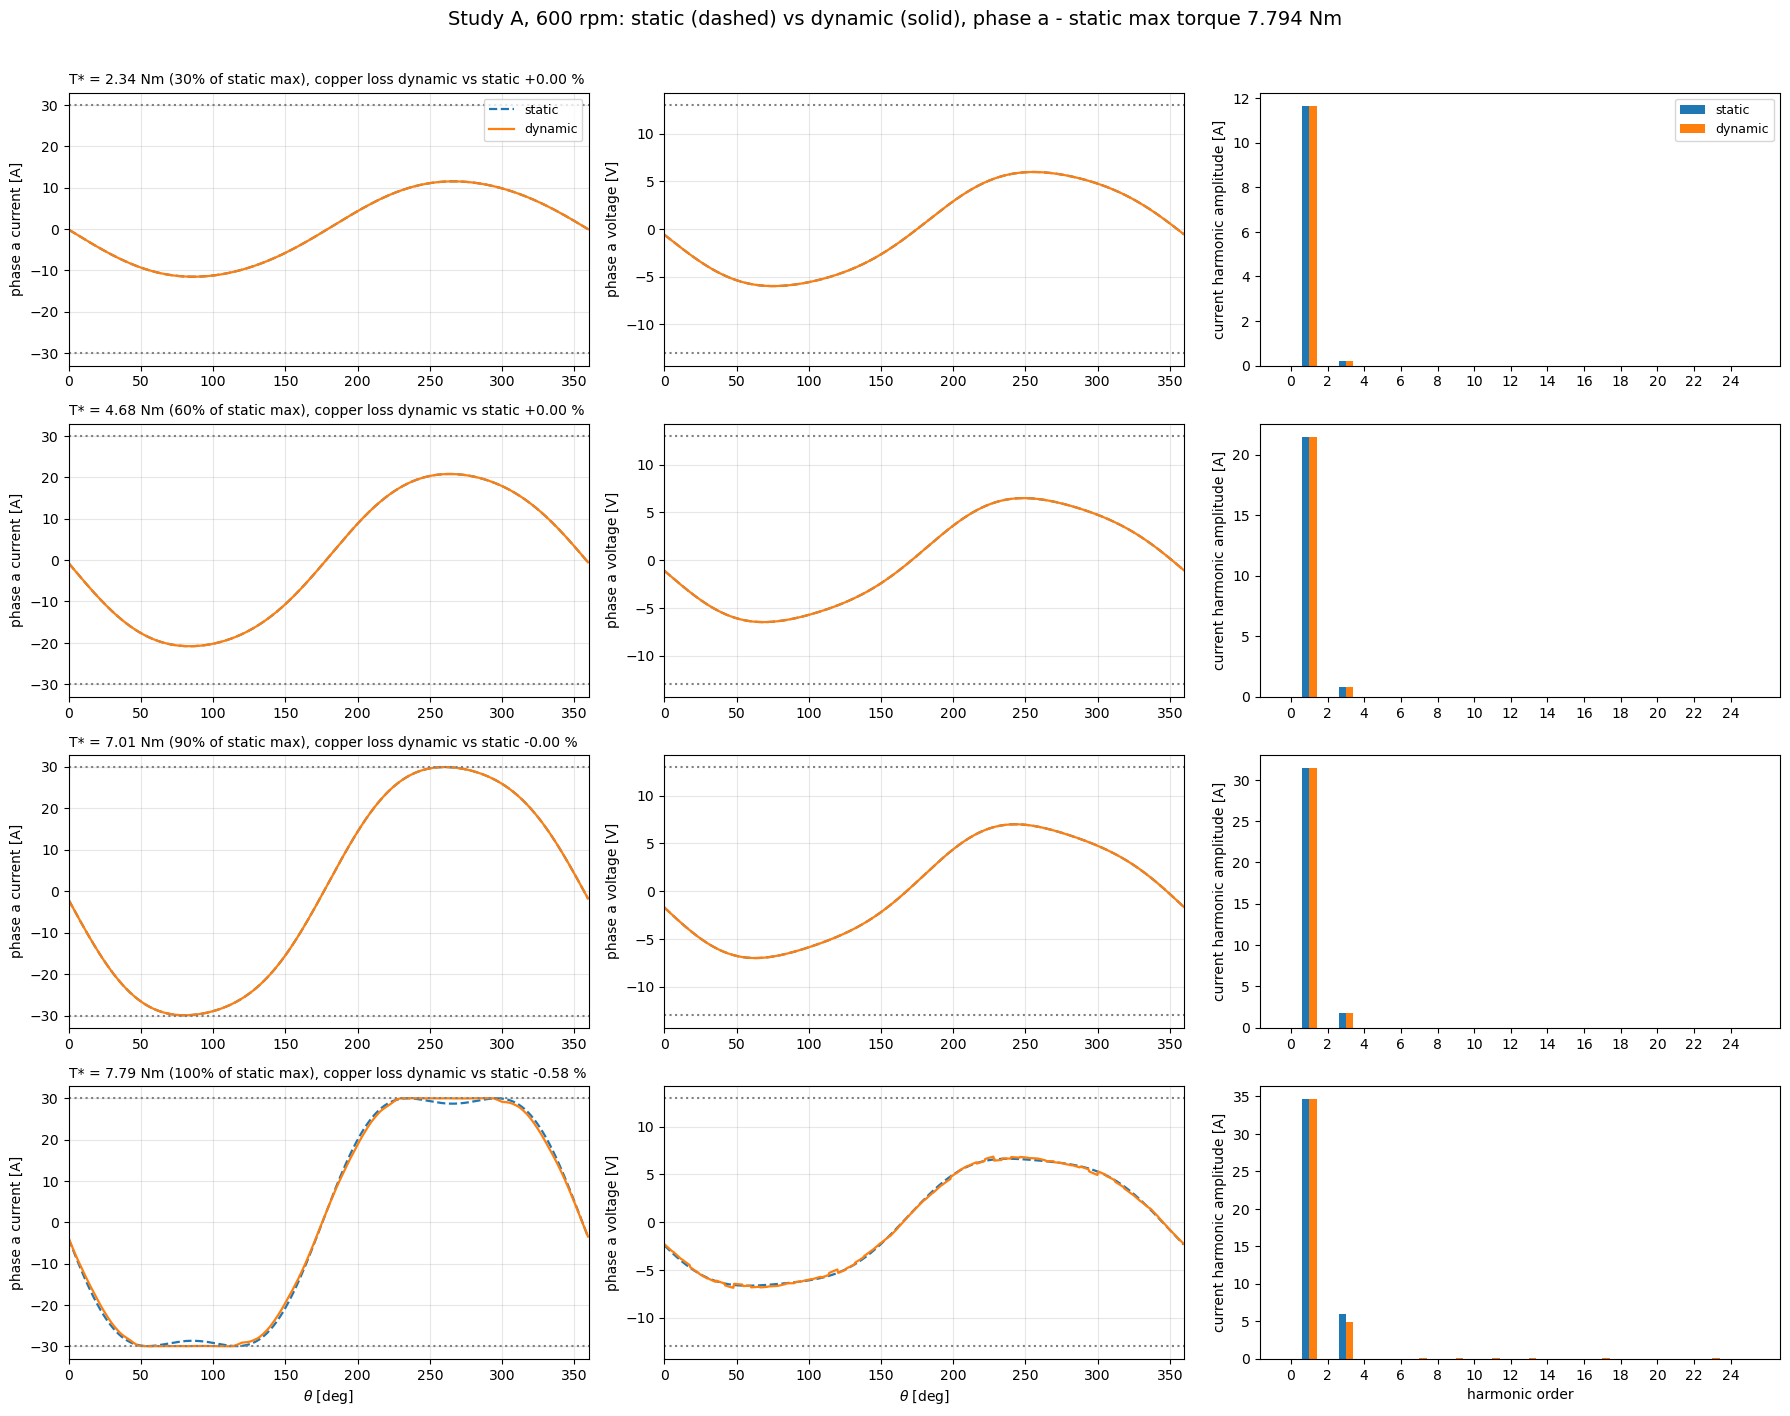

  1200 rpm, 30%: 10s
  1200 rpm, 60%: 10s
  1200 rpm, 90%: 10s
  1200 rpm, 100%: 23s


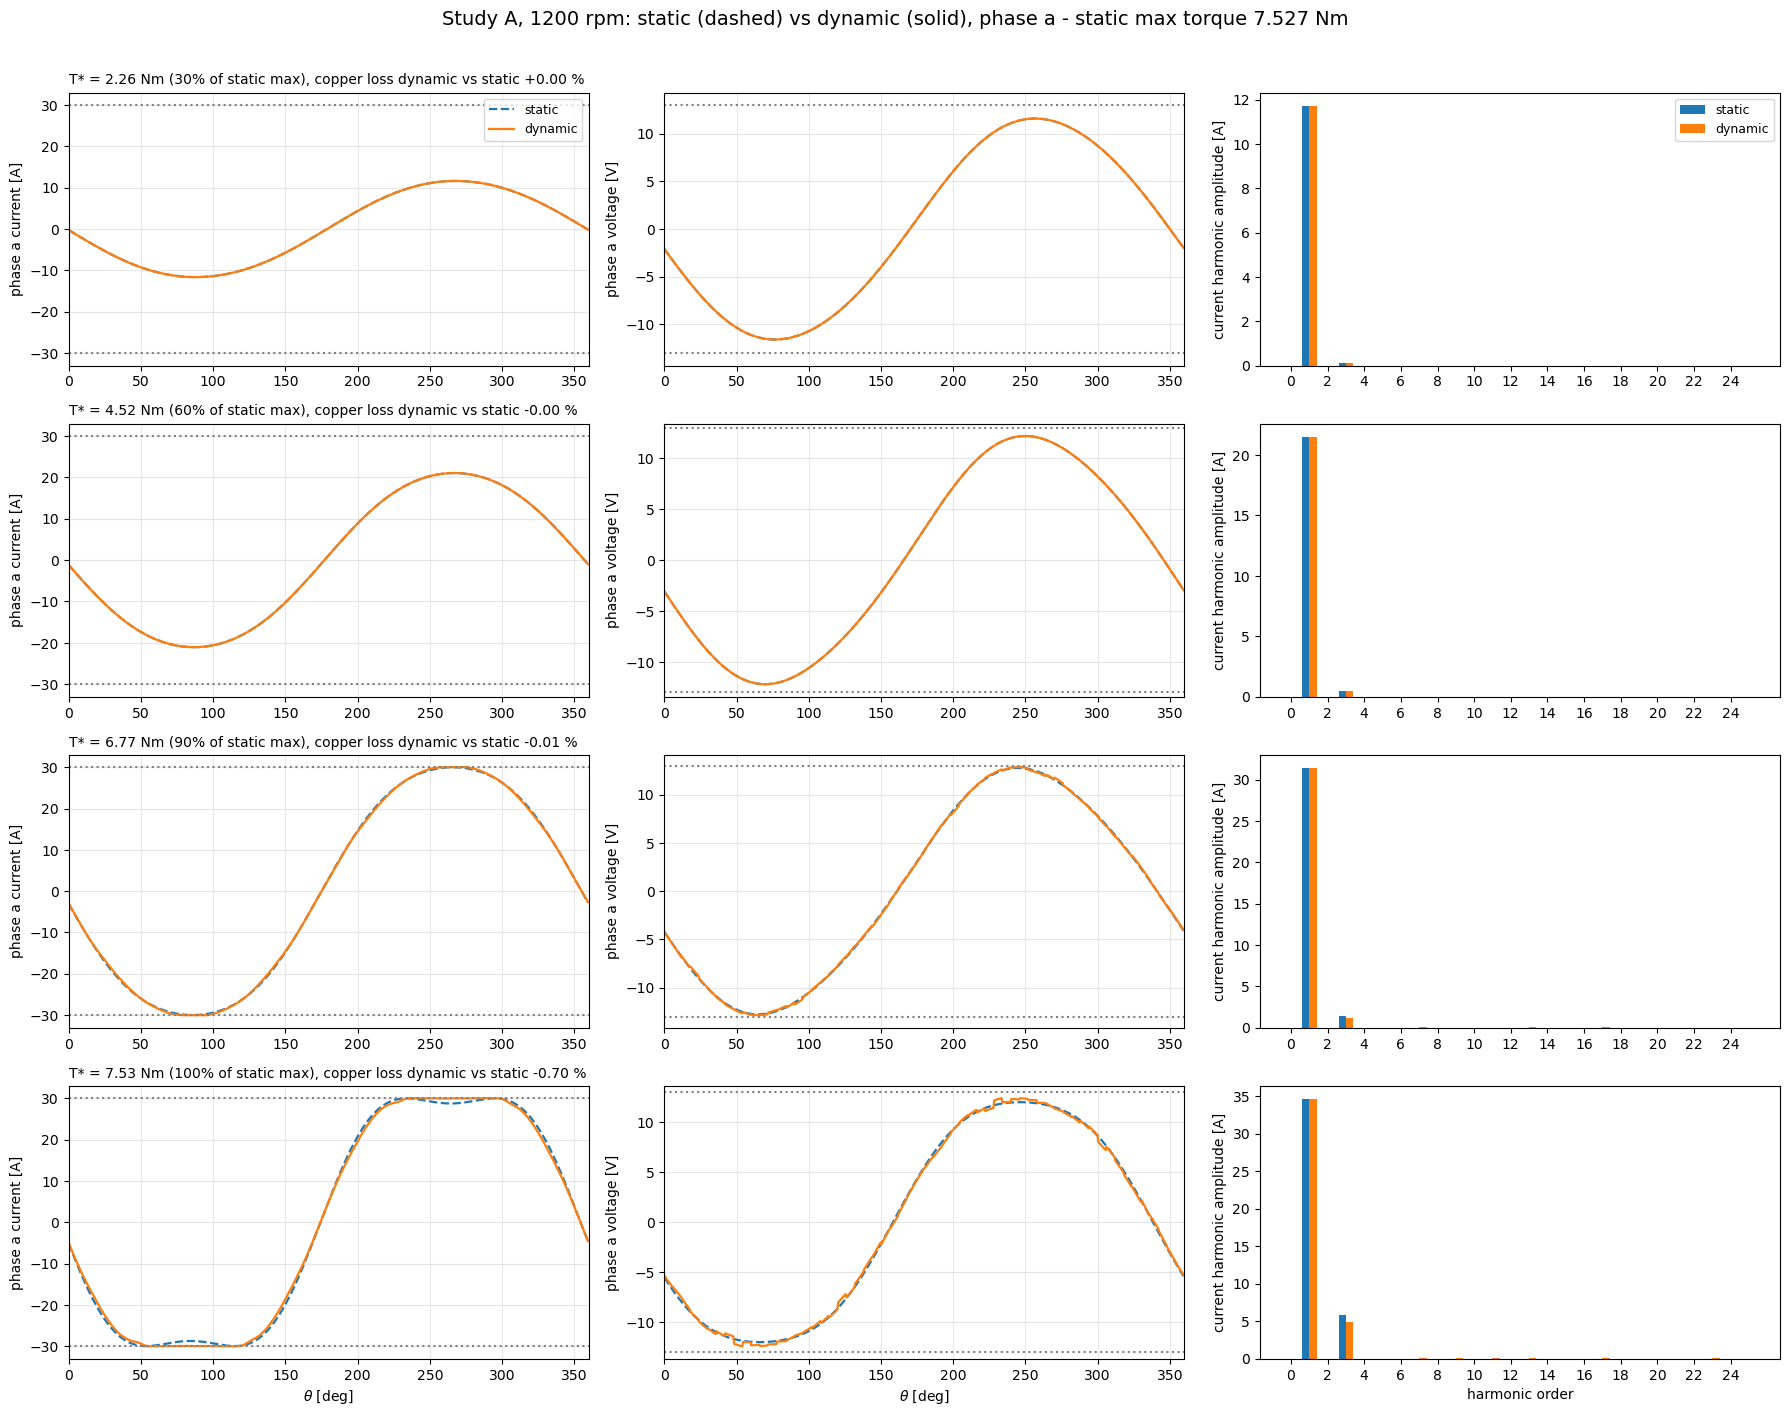

  1800 rpm, 30%: 8s
  1800 rpm, 60%: 13s
  1800 rpm, 90%: 16s
  1800 rpm, 100%: 24s


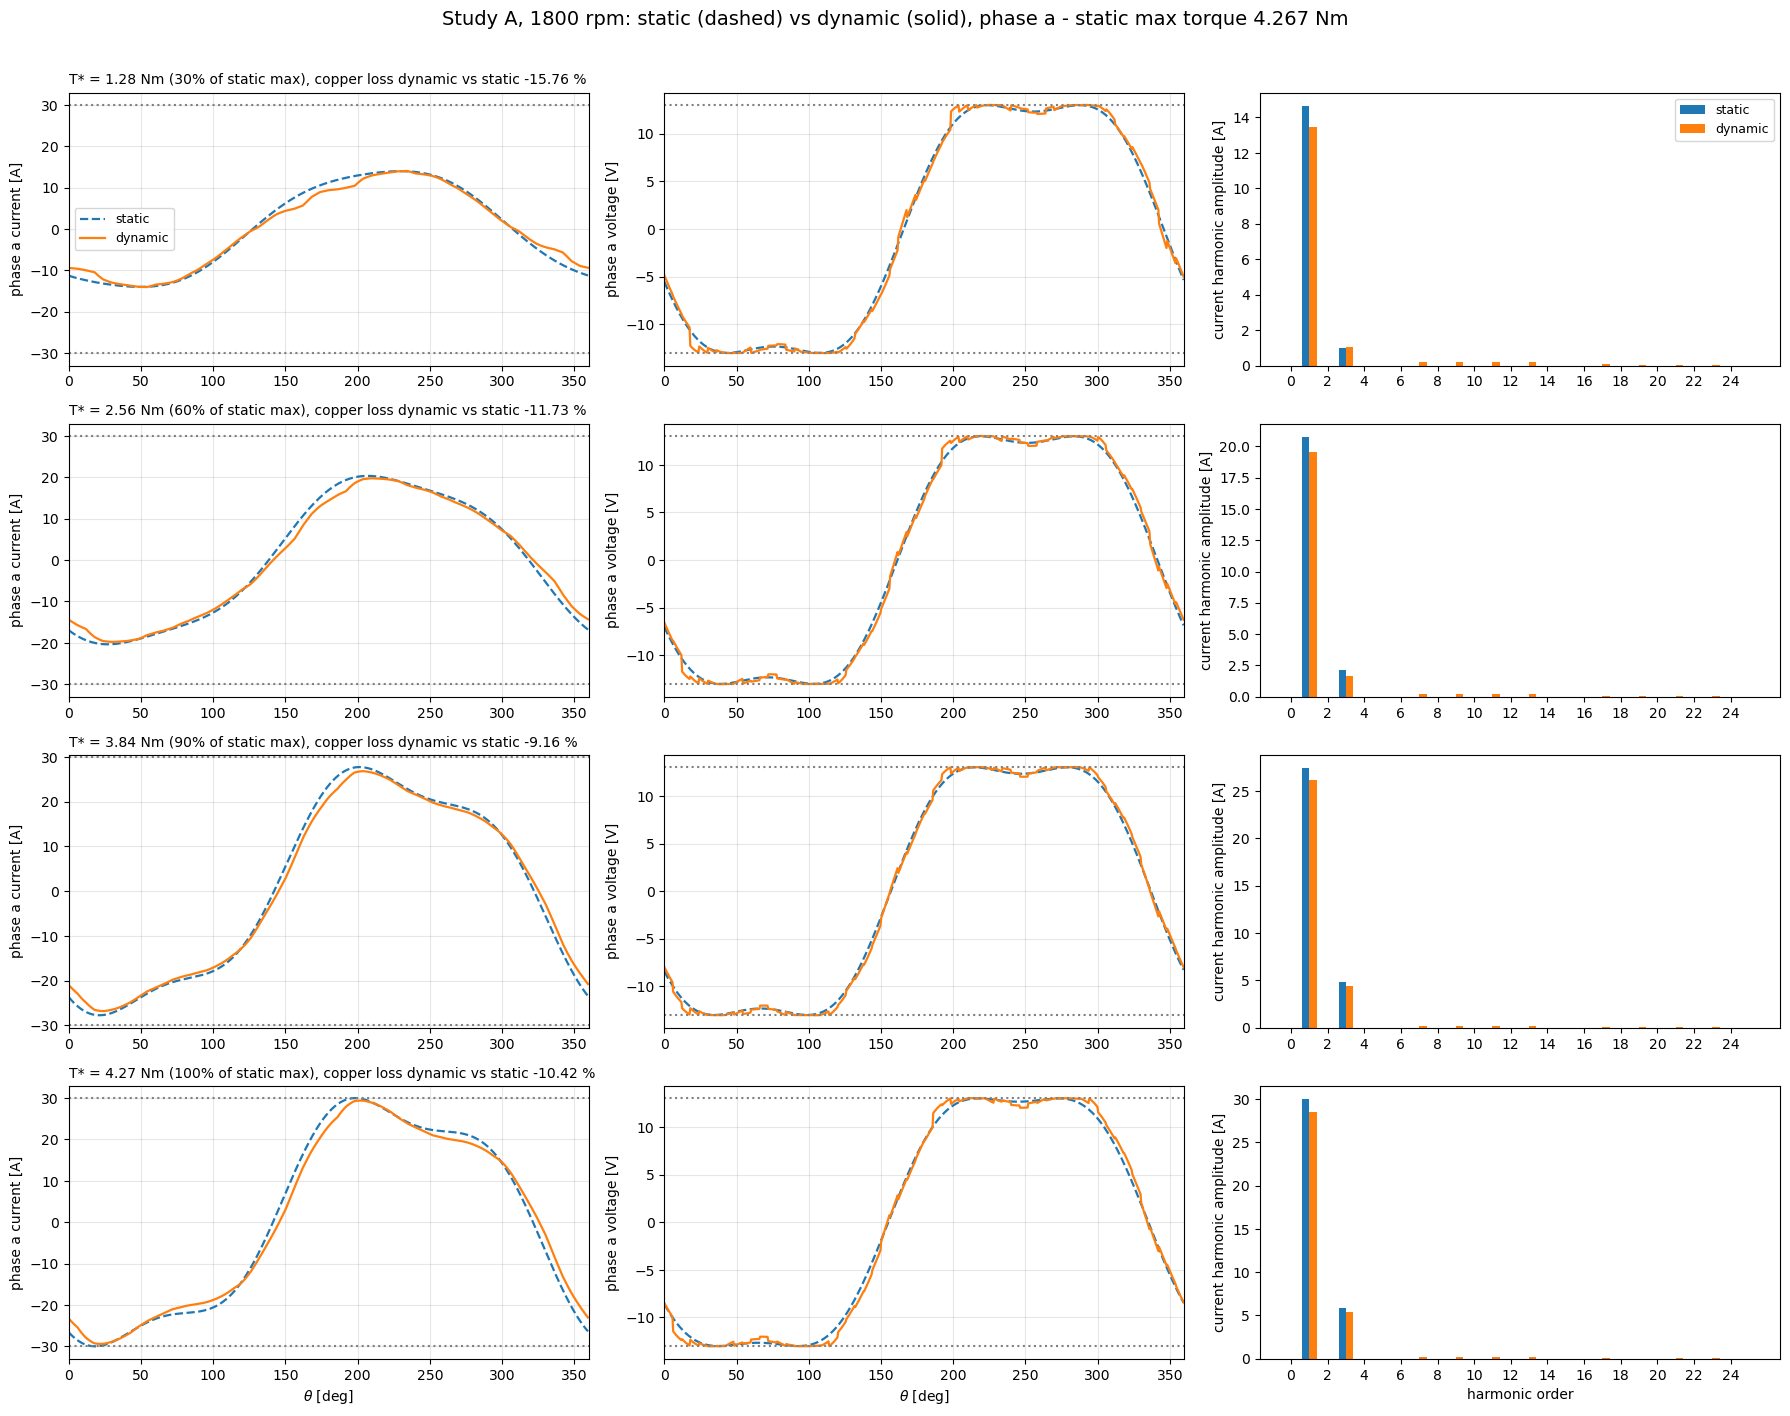


  rpm     T*     mode   copper  I_peak  V_peak  3rd/1st other/1st
  600   2.34   static    340.7   11.53    5.98    0.018    0.0000
  600   2.34  dynamic    340.7   11.53    5.98    0.018    0.0000
  600   4.68   static   1157.5   20.82    6.49    0.037    0.0000
  600   4.68  dynamic   1157.5   20.82    6.49    0.037    0.0000
  600   7.01   static   2485.2   29.89    7.01    0.056    0.0000
  600   7.01  dynamic   2485.2   29.89    7.01    0.056    0.0000
  600   7.79   static   3087.2   30.00    6.65    0.171    0.0000
  600   7.79  dynamic   3069.2   30.05    6.87    0.141    0.0068
 1200   2.26   static    344.1   11.62   11.57    0.010    0.0000
 1200   2.26  dynamic    344.1   11.62   11.57    0.010    0.0000
 1200   4.52   static   1158.9   21.05   12.20    0.022    0.0000
 1200   4.52  dynamic   1158.9   21.05   12.20    0.022    0.0000
 1200   6.77   static   2477.1   30.00   12.77    0.046    0.0000
 1200   6.77  dynamic   2476.8   30.04   12.86    0.038    0.0048
 1200   7

In [3]:
# Study A: where does the waveform deformation come from? Torque raised step by step at each
# speed; static (constant dq current, dashed) vs dynamic (ActiveSetOptimizer, solid), phase a.
study_a = []
H_SHOW = np.arange(26)  # harmonics shown in the spectrum panel
for rpm in SPEEDS_RPM:
    omega = rpm / const_mech_speed
    t_max = optimizer_static.maximize_torque(omega).torque
    fig, axes = plt.subplots(len(TORQUE_FRACS), 3, figsize=(18, 3.6 * len(TORQUE_FRACS)), squeeze=False)
    fig.suptitle(f"Study A, {rpm:.0f} rpm: static (dashed) vs dynamic (solid), phase a "
                 f"- static max torque {t_max:.3f} Nm", fontsize=14)
    for r, frac in enumerate(TORQUE_FRACS):
        T = frac * t_max
        t0 = time.perf_counter()
        sols = {"static": optimizer_static.minimize_current(T, omega),
                "dynamic": optimizer_dynamic.minimize_current(T, omega)}
        row = {"rpm": rpm, "frac": frac, "T": T, "dynamic_joint_solves": n_joint_solves(sols["dynamic"])}
        ax_i, ax_v, ax_s = axes[r]
        for name, ls, off in (("static", "--", -0.2), ("dynamic", "-", 0.2)):
            sol = sols[name]
            row[f"{name}_ok"] = sol.success
            if not sol.success:
                continue
            i_ph, v_ph = dense_waveforms(omega, sol.curr_dq)
            m = metrics(i_ph, v_ph)
            row.update({f"{name}_{k}": v for k, v in m.items() if k != "spectrum"})
            ax_i.plot(DEG, i_ph[0], ls, lw=1.6, label=name)
            ax_v.plot(DEG, v_ph[0], ls, lw=1.6, label=name)
            ax_s.bar(H_SHOW + off, m["spectrum"][H_SHOW], width=0.4, label=name)
        cl = ""
        if row.get("static_ok") and row.get("dynamic_ok"):
            d = 100 * (row["dynamic_copper_loss"] / row["static_copper_loss"] - 1)
            cl = f", copper loss dynamic vs static {d:+.2f} %"
        ax_i.set_title(f"T* = {T:.2f} Nm ({frac:.0%} of static max){cl}", fontsize=10, loc="left")
        for ax, lim in ((ax_i, CURR_MAX), (ax_v, VOLT_MAX)):
            ax.axhline(lim, color="gray", ls=":"); ax.axhline(-lim, color="gray", ls=":")
            ax.set_xlim(0, 360); ax.grid(alpha=0.3)
        ax_i.set_ylabel("phase a current [A]"); ax_v.set_ylabel("phase a voltage [V]")
        ax_s.set_ylabel("current harmonic amplitude [A]"); ax_s.set_xticks(H_SHOW[::2])
        if r == 0:
            ax_i.legend(fontsize=9); ax_s.legend(fontsize=9)
        if r == len(TORQUE_FRACS) - 1:
            ax_i.set_xlabel(r"$\theta$ [deg]"); ax_v.set_xlabel(r"$\theta$ [deg]"); ax_s.set_xlabel("harmonic order")
        study_a.append(row)
        print(f"  {rpm:.0f} rpm, {frac:.0%}: {time.perf_counter() - t0:.0f}s", flush=True)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    fig.savefig(os.path.join(figs_dir, f"studyA_{rpm:.0f}rpm.png"), dpi=110)
    plt.show()

print(f"\n{'rpm':>5} {'T*':>6} {'mode':>8} {'copper':>8} {'I_peak':>7} {'V_peak':>7} {'3rd/1st':>8} {'other/1st':>9}")
for r in study_a:
    for name in ("static", "dynamic"):
        if r.get(f"{name}_ok"):
            print(f"{r['rpm']:5.0f} {r['T']:6.2f} {name:>8} {r[name + '_copper_loss']:8.1f} {r[name + '_I_peak']:7.2f} "
                  f"{r[name + '_V_peak']:7.2f} {r[name + '_h3_share']:8.3f} {r[name + '_other_share']:9.4f}")
        else:
            print(f"{r['rpm']:5.0f} {r['T']:6.2f} {name:>8}   no solution")

  1200 rpm, rho=0: ok, 0 joint solves, 9s
  1200 rpm, rho=100: ok, 0 joint solves, 9s
  1200 rpm, rho=1000: ok, 0 joint solves, 9s
  1200 rpm, rho=10000: ok, 0 joint solves, 9s
  1200 rpm, rho=100000: ok, 0 joint solves, 9s
  1200 rpm, rho=1e+06: ok, 0 joint solves, 9s


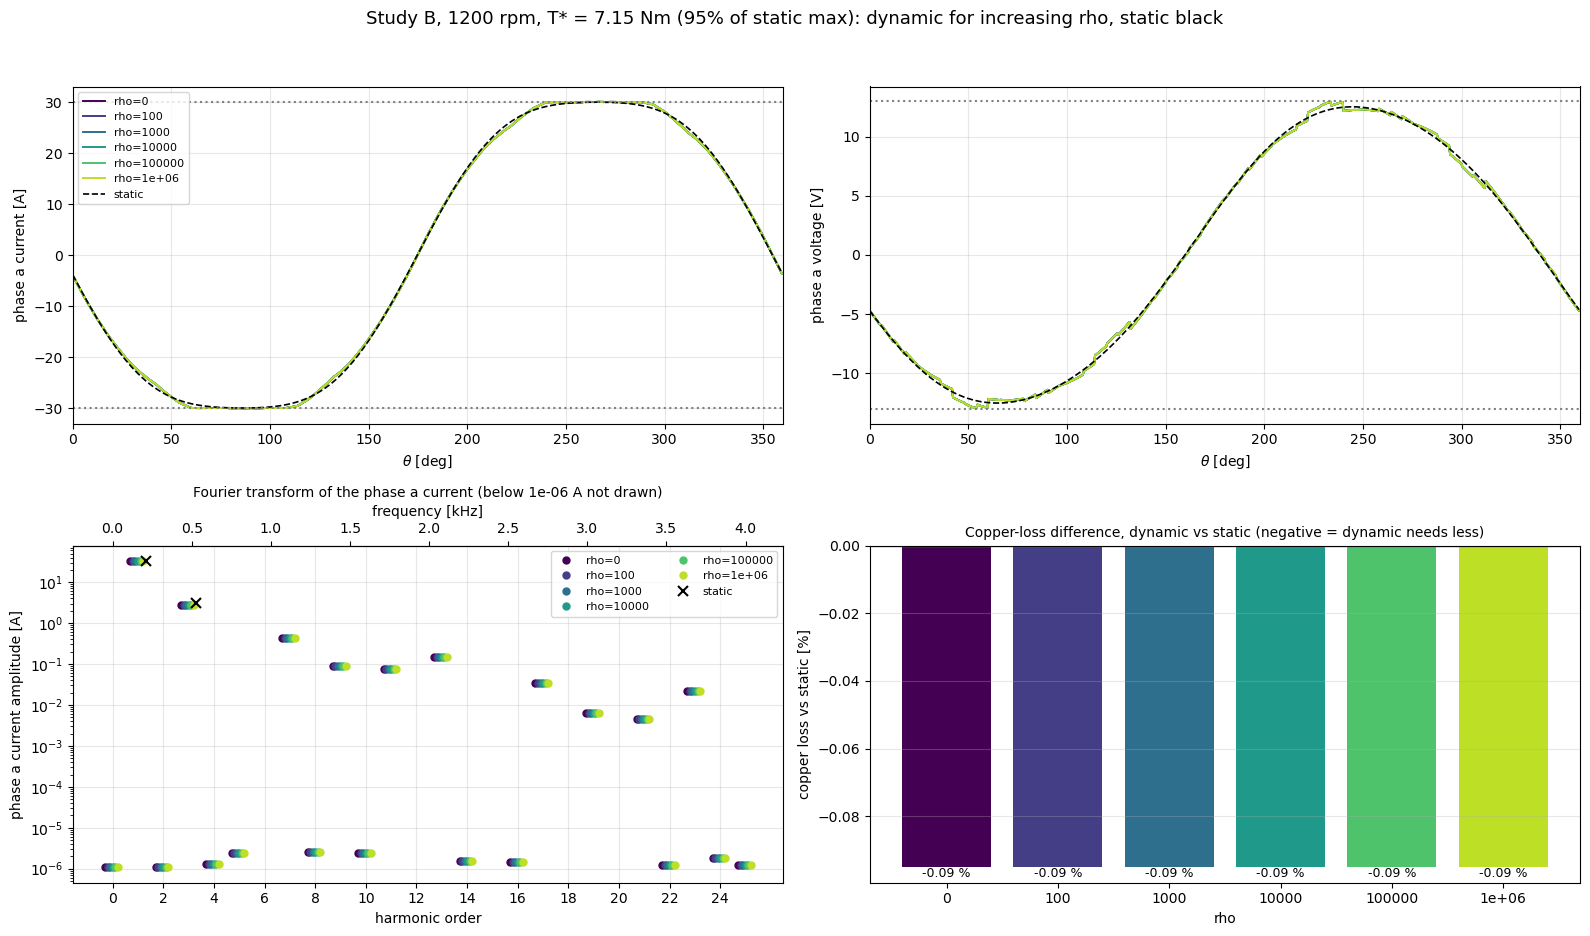

  1500 rpm, rho=0: ok, 2 joint solves, 37s
  1500 rpm, rho=100: ok, 2 joint solves, 18s
  1500 rpm, rho=1000: ok, 2 joint solves, 12s
  1500 rpm, rho=10000: ok, 1 joint solves, 9s
  1500 rpm, rho=100000: ok, 1 joint solves, 11s
  1500 rpm, rho=1e+06: ok, 1 joint solves, 16s


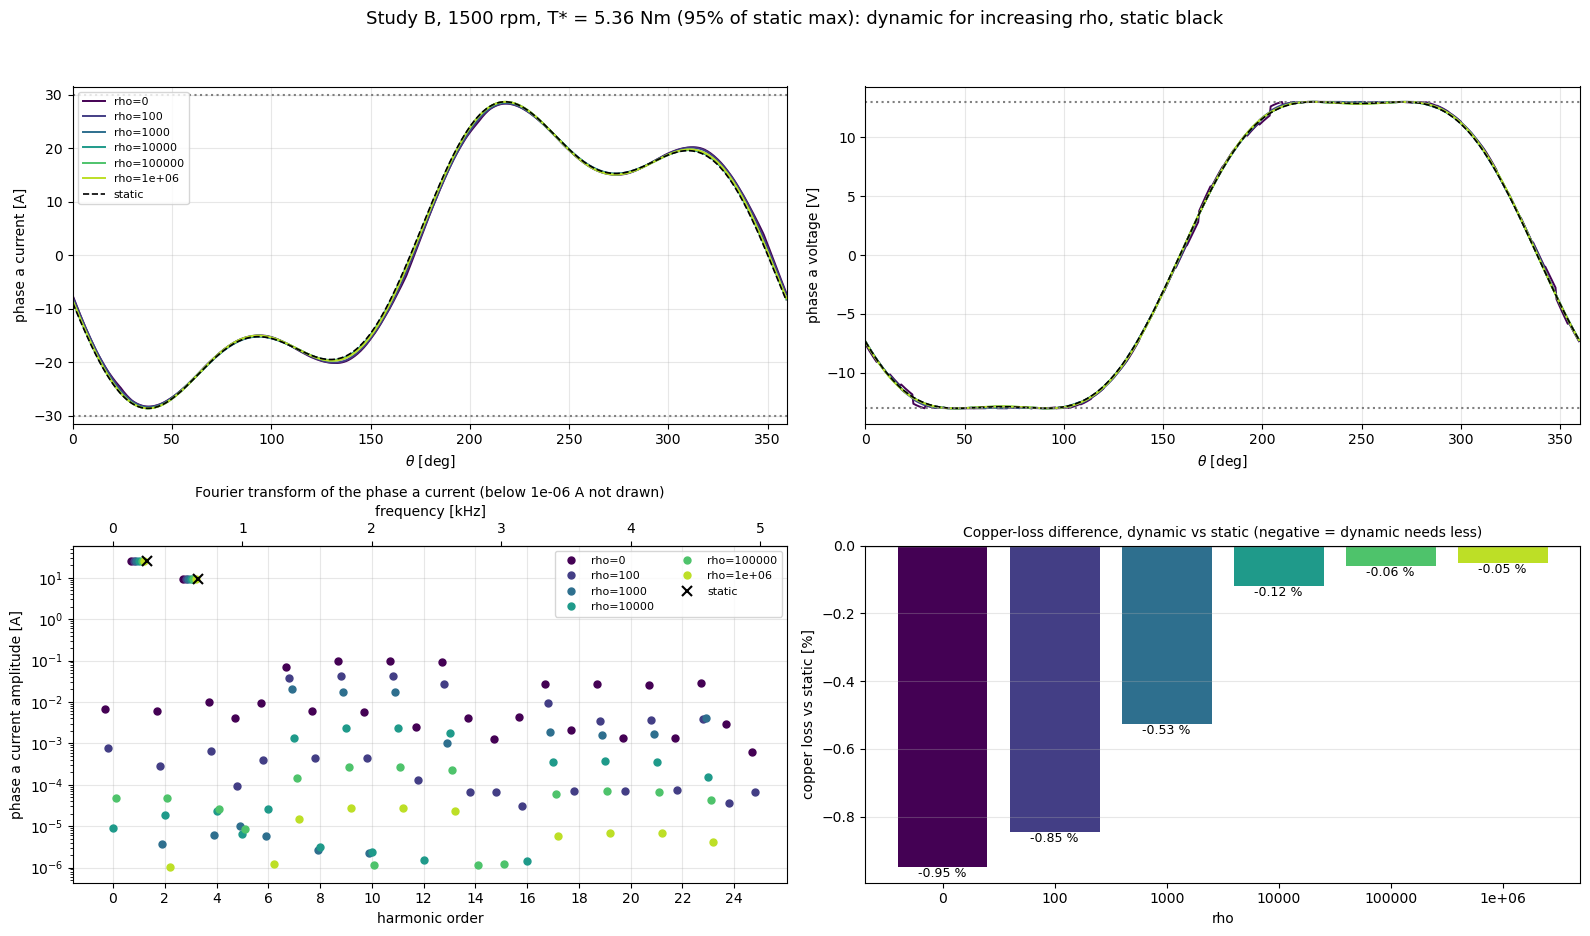

  1800 rpm, rho=0: ok, 4 joint solves, 12s
  1800 rpm, rho=100: ok, 3 joint solves, 12s
  1800 rpm, rho=1000: ok, 2 joint solves, 10s
  1800 rpm, rho=10000: ok, 2 joint solves, 8s
  1800 rpm, rho=100000: ok, 2 joint solves, 9s
  1800 rpm, rho=1e+06: ok, 2 joint solves, 21s


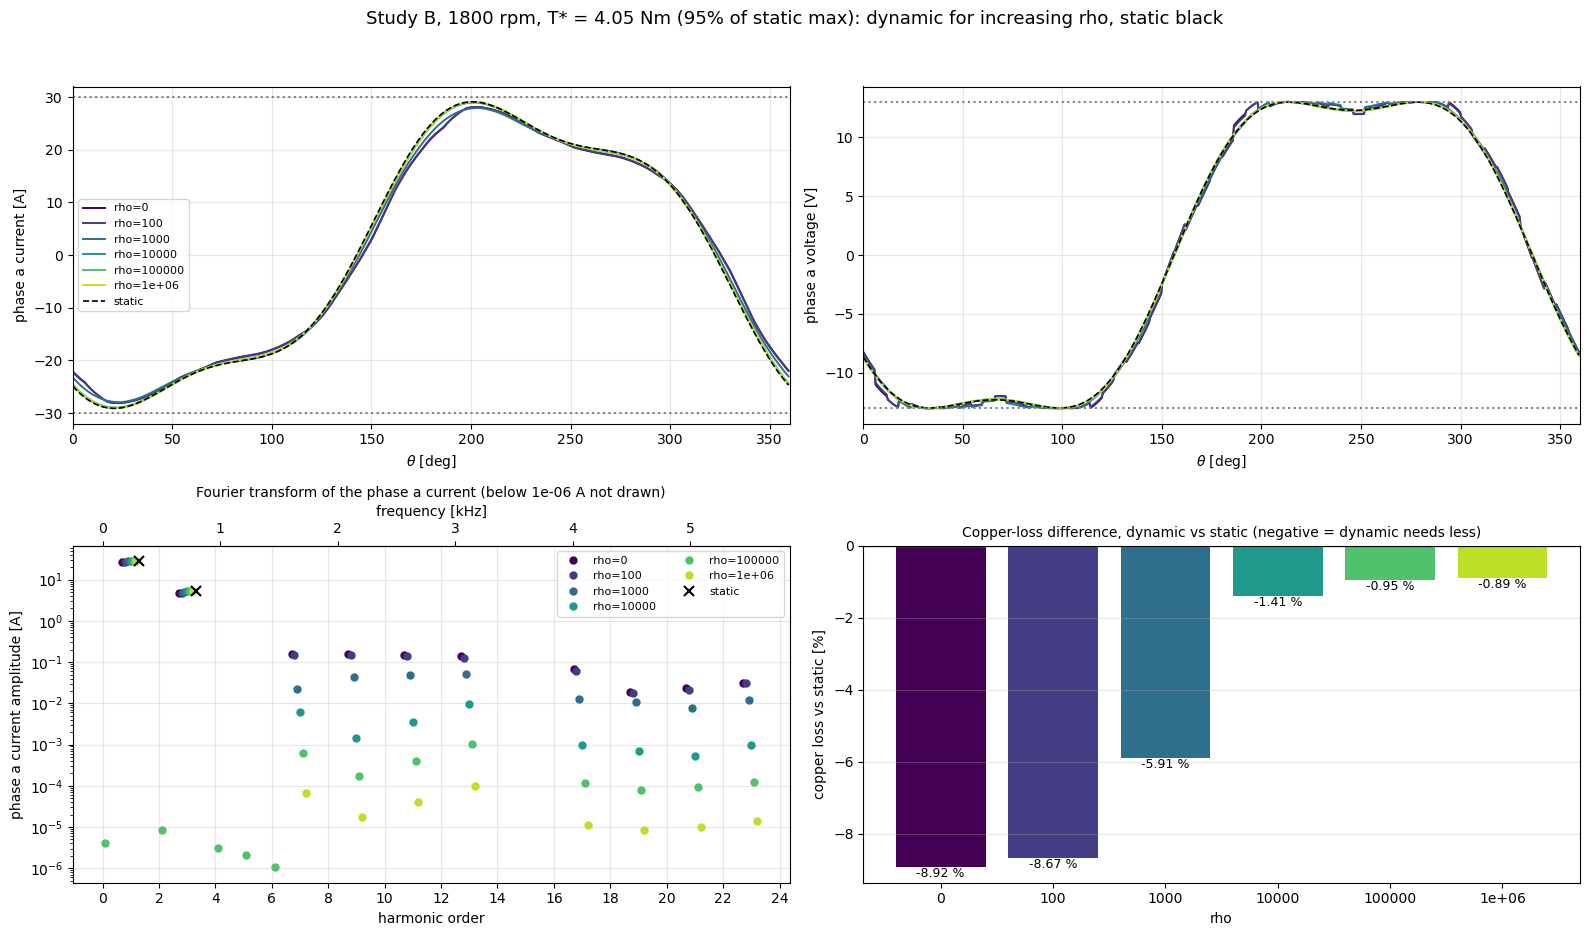

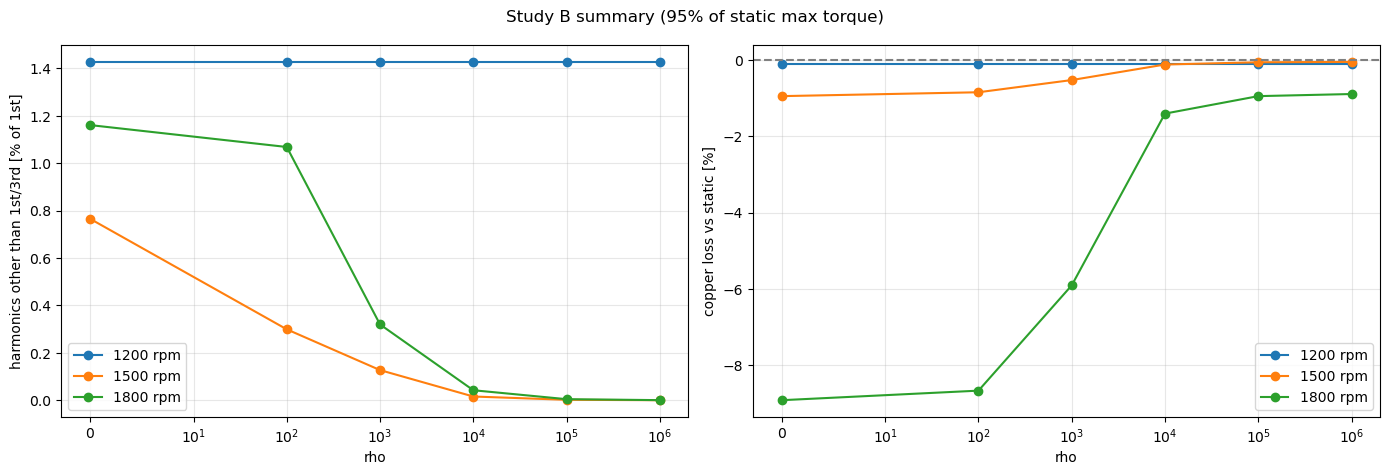


  rpm     rho    ok joint  copper vs static  other/1st  V_peak  I_peak
 1200       0   yes     0            -0.09%     0.0143  12.964   30.06
 1200     100   yes     0            -0.09%     0.0143  12.964   30.06
 1200    1000   yes     0            -0.09%     0.0143  12.964   30.06
 1200   10000   yes     0            -0.09%     0.0143  12.964   30.06
 1200  100000   yes     0            -0.09%     0.0143  12.964   30.06
 1200   1e+06   yes     0            -0.09%     0.0143  12.964   30.06
 1500       0   yes     2            -0.95%     0.0077  13.008   28.34
 1500     100   yes     2            -0.85%     0.0030  13.008   28.38
 1500    1000   yes     2            -0.53%     0.0013  13.002   28.51
 1500   10000   yes     1            -0.12%     0.0002  13.005   28.64
 1500  100000   yes     1            -0.06%     0.0000  13.007   28.65
 1500   1e+06   yes     1            -0.05%     0.0000  13.007   28.65
 1800       0   yes     4            -8.92%     0.0116  13.030   28.12
 1800

In [4]:
# Study B: smoother dynamic waveforms at what cost? Smoothness penalty rho (PDF 11 §6, E02):
#   minimize  sum_n |i_n|^2 + rho * sum_n |i_n+1 - i_n|^2
# rho acts only in the joint solve, i.e. where the voltage limit makes the dynamic current vary.
# Where R0 already satisfies everything (0 joint solves), dynamic = static and rho has no effect.
# For large rho the trajectory becomes constant; what then still separates it from static is only
# that dynamic mode checks the voltage at the N_GRID node angles, static at 700 angles.
SPEC_FLOOR = 1e-6  # harmonic amplitudes below this [A] are numerical zero and not drawn
H_SPEC = np.arange(26)
study_b = []
for rpm in RHO_SPEEDS_RPM:
    omega = rpm / const_mech_speed
    f_el = rpm * drive.n_ppairs / 60.0  # electrical frequency [Hz]
    t_max = optimizer_static.maximize_torque(omega).torque
    T = RHO_TORQUE_FRAC * t_max
    sol_s = optimizer_static.minimize_current(T, omega)
    i_s, v_s = dense_waveforms(omega, sol_s.curr_dq)
    m_s = metrics(i_s, v_s)
    fig, ((ax_i, ax_v), (ax_s, ax_c)) = plt.subplots(2, 2, figsize=(16, 9.5))
    fig.suptitle(f"Study B, {rpm:.0f} rpm, T* = {T:.2f} Nm ({RHO_TORQUE_FRAC:.0%} of static max): "
                 f"dynamic for increasing rho, static black", fontsize=13)
    colors = plt.cm.viridis(np.linspace(0.0, 0.9, len(RHO_VALUES)))
    offsets = np.linspace(-0.3, 0.3, len(RHO_VALUES) + 1)  # side by side per harmonic, last one = static
    bar_labels, bar_values, bar_colors = [], [], []
    for k, (rho, col) in enumerate(zip(RHO_VALUES, colors)):
        t0 = time.perf_counter()
        sol = ActiveSetOptimizer(fwd, opts=SLSQP_OPTS, n_grid=N_GRID, rho=rho).minimize_current(T, omega)
        row = {"rpm": rpm, "rho": rho, "T": T, "ok": sol.success, "joint_solves": n_joint_solves(sol)}
        if sol.success:
            i_ph, v_ph = dense_waveforms(omega, sol.curr_dq)
            m = metrics(i_ph, v_ph)
            row.update({key: val for key, val in m.items() if key != "spectrum"})
            row["copper_vs_static_pct"] = 100 * (m["copper_loss"] / m_s["copper_loss"] - 1)
            ax_i.plot(DEG, i_ph[0], color=col, lw=1.4, label=f"rho={rho:g}")
            ax_v.plot(DEG, v_ph[0], color=col, lw=1.4)
            spec = m["spectrum"][H_SPEC]
            shown = spec > SPEC_FLOOR
            ax_s.plot(H_SPEC[shown] + offsets[k], spec[shown], "o", color=col, ms=5, label=f"rho={rho:g}")
            bar_labels.append(f"{rho:g}")
            bar_values.append(row["copper_vs_static_pct"])
            bar_colors.append(col)
        study_b.append(row)
        print(f"  {rpm:.0f} rpm, rho={rho:g}: {'ok' if sol.success else 'FAILED'}, "
              f"{row['joint_solves']} joint solves, {time.perf_counter() - t0:.0f}s", flush=True)
    ax_i.plot(DEG, i_s[0], "k--", lw=1.2, label="static")
    ax_v.plot(DEG, v_s[0], "k--", lw=1.2)
    spec_s = m_s["spectrum"][H_SPEC]
    shown = spec_s > SPEC_FLOOR
    ax_s.plot(H_SPEC[shown] + offsets[-1], spec_s[shown], "kx", ms=7, mew=1.5, label="static")
    for ax, lim, ylab in ((ax_i, CURR_MAX, "phase a current [A]"), (ax_v, VOLT_MAX, "phase a voltage [V]")):
        ax.axhline(lim, color="gray", ls=":"); ax.axhline(-lim, color="gray", ls=":")
        ax.set_xlim(0, 360); ax.set_xlabel(r"$\theta$ [deg]"); ax.set_ylabel(ylab); ax.grid(alpha=0.3)
    ax_i.legend(fontsize=8)
    ax_s.set_yscale("log")
    ax_s.set_xticks(H_SPEC[::2]); ax_s.set_xlabel("harmonic order"); ax_s.set_ylabel("phase a current amplitude [A]")
    ax_s.grid(alpha=0.3); ax_s.legend(fontsize=8, ncol=2)
    top = ax_s.secondary_xaxis("top", functions=(lambda h, f=f_el: h * f / 1000.0, lambda khz, f=f_el: khz * 1000.0 / f))
    top.set_xlabel("frequency [kHz]")
    ax_s.set_title(f"Fourier transform of the phase a current (below {SPEC_FLOOR:g} A not drawn)", fontsize=10)
    bars = ax_c.bar(bar_labels, bar_values, color=bar_colors)
    ax_c.bar_label(bars, labels=[f"{v:+.2f} %" for v in bar_values], fontsize=9)
    ax_c.axhline(0.0, color="gray", lw=1)
    ax_c.set_xlabel("rho"); ax_c.set_ylabel("copper loss vs static [%]")
    ax_c.set_title("Copper-loss difference, dynamic vs static (negative = dynamic needs less)", fontsize=10)
    ax_c.grid(axis="y", alpha=0.3)
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    fig.savefig(os.path.join(figs_dir, f"studyB_{rpm:.0f}rpm.png"), dpi=110)
    plt.show()

# Trade-off summary: harmonic content other than 1st/3rd (the dynamic ripple) and copper loss
# relative to static, against rho.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))
for rpm in RHO_SPEEDS_RPM:
    rows = [r for r in study_b if r["rpm"] == rpm and r["ok"]]
    rhos = [r["rho"] for r in rows]
    ax1.plot(rhos, [100 * r["other_share"] for r in rows], "o-", label=f"{rpm:.0f} rpm")
    ax2.plot(rhos, [r["copper_vs_static_pct"] for r in rows], "o-", label=f"{rpm:.0f} rpm")
for ax in (ax1, ax2):
    ax.set_xscale("symlog", linthresh=10.0); ax.set_xlabel("rho"); ax.grid(alpha=0.3); ax.legend()
ax1.set_ylabel("harmonics other than 1st/3rd [% of 1st]")
ax2.set_ylabel("copper loss vs static [%]")
ax2.axhline(0.0, color="gray", ls="--")
fig.suptitle(f"Study B summary ({RHO_TORQUE_FRAC:.0%} of static max torque)")
plt.tight_layout()
fig.savefig(os.path.join(figs_dir, "studyB_summary.png"), dpi=110)
plt.show()

print(f"\n{'rpm':>5} {'rho':>7} {'ok':>5} {'joint':>5} {'copper vs static':>17} {'other/1st':>10} {'V_peak':>7} {'I_peak':>7}")
for r in study_b:
    if r["ok"]:
        print(f"{r['rpm']:5.0f} {r['rho']:7g} {'yes':>5} {r['joint_solves']:5d} {r['copper_vs_static_pct']:16.2f}% "
              f"{r['other_share']:10.4f} {r['V_peak']:7.3f} {r['I_peak']:7.2f}")
    else:
        print(f"{r['rpm']:5.0f} {r['rho']:7g} {'no':>5} {r['joint_solves']:5d}")